# 05 Logistic Regression
Logistic regression combines the pre-game features into a probability that the
home team wins. The implementation uses scikit-learn, the combined feature table
from notebook 02, and the same season split and evaluation functions as
notebooks 03 and 04.
Train and validation results are reported here; test evaluation stays reserved
for the team's final comparison.

### Step 1: imports

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, confusion_matrix)

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8a85"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "legend.frameon": False})

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

### Step 2: load the combined feature table
`model_table.csv` already contains cleaned games, pre-game features, and the fixed
split. The table is loaded directly without merging or rebuilding the raw data.
Missing values are mostly season-opening games with no earlier history. These
rows remain in the dataset, with missing values filled using training medians
when fitting the model.

In [ ]:
data = pd.read_csv("../src/dataset/model_table.csv", parse_dates=["GAME_DATE"])

print(data.shape, "(games, columns)")
data.isna().sum().sort_values(ascending=False).head(8).to_frame("missing values")

(24848, 80) (games, columns)


,missing values
AWAY_ST_ROAD_W_PCT,599
HOME_ST_HOME_W_PCT,599
HOME_ST_ROAD_W_PCT,458
AWAY_ST_HOME_W_PCT,425
DIFF_PTS_LAST10,342
DIFF_PLUS_MINUS_LAST10,342
DIFF_ST_W_PCT,342
DIFF_SEASON_W_PCT,342


### Step 3: split by season (never shuffled)
The existing `SPLIT` column assigns 2003–2016 to training, 2017–2018 to
validation, and 2019–2022 to the reserved test set. The target is `HOME_TEAM_WINS` (1 = home win).
Date, season, and split are metadata, not model inputs. All 76 inputs are already
numeric, so no categorical encoding is needed. Historical box scores such as
`HOME_PTS_LAST10` are allowed; raw same-game box scores and IDs are not.

In [12]:
feature_cols = [c for c in data.columns if c not in ("GAME_DATE", "SEASON", "SPLIT", "HOME_TEAM_WINS")]
X = data[feature_cols]
y = data["HOME_TEAM_WINS"]
is_train, is_val, is_test = (data["SPLIT"] == s for s in ("train", "validation", "test"))


data.groupby("SPLIT", sort=False).agg(games=("SPLIT", "size"),
    first_season=("SEASON", "min"), last_season=("SEASON", "max"))

,games,first_season,last_season
SPLIT,,,
train,18110,2003,2016
validation,2624,2017,2018
test,4114,2019,2022


### Step 4: evaluation (same cell in every model notebook)
Every model gives a probability that the home team wins. A probability of at
least 0.5 produces a "home win" prediction. Evaluation reports accuracy, precision,
recall, F1, ROC-AUC and log loss. AUC and log loss use probabilities rather than class predictions.

In [13]:
def evaluate(name, y_true, y_prob, threshold=0.5):
    y_prob = np.clip(np.asarray(y_prob, dtype=float), 1e-6, 1 - 1e-6)
    y_pred = (y_prob >= threshold).astype(int)
    return {"model": name,
            "accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "roc_auc": roc_auc_score(y_true, y_prob),
            "log_loss": log_loss(y_true, y_prob, labels=[0, 1])}

def plot_cm(ax, y_true, y_prob, title):
    cm = confusion_matrix(y_true, (np.asarray(y_prob) >= 0.5).astype(int), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["away win", "home win"], yticklabels=["away win", "home win"])
    ax.set_xlabel("predicted"); ax.set_ylabel("actual"); ax.set_title(title)

### Step 5: preprocess and train the default model
The pipeline fills missing values with the training median, standardizes the
features, and fits logistic regression. Putting these steps together also keeps
preprocessing inside each training fold during tuning.

The default model uses C=1, L2 regularization, and an intercept. `max_iter=10000`
gives the optimizer enough iterations to converge; it does not set model
complexity. The roughly 60/40 class proportions remain unchanged, with no
SMOTE or class weighting. Neither validation nor test is used for fitting.

In [14]:
lr_default = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(C=1.0, solver="lbfgs", max_iter=10000, class_weight=None)),
])

lr_default.fit(X[is_train], y[is_train])
print("Training games:", int(is_train.sum()))
print("Iterations used:", lr_default.named_steps["model"].n_iter_[0])

Training games: 18110
Iterations used: 62


### Step 6: tune C with forward-chaining folds
C controls regularization: smaller C constrains the coefficients more. Six
settings are compared using the same five training-season folds as notebook 04:

| Fold | Train on | Validate on |
|---|---|---|
| 1 | 2003–2011 | 2012 |
| 2 | 2003–2012 | 2013 |
| 3 | 2003–2013 | 2014 |
| 4 | 2003–2014 | 2015 |
| 5 | 2003–2015 | 2016 |

Each fit uses a fresh pipeline, including new training-only medians and scaling.
The setting with the lowest **mean fold log loss** is selected; exact ties favor
the smaller C.
The validation and test seasons do not select the settings.

In [15]:
import time

grid = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
fold_seasons = [2012, 2013, 2014, 2015, 2016]
season = data["SEASON"]

t0 = time.time()
rows = []
for C in grid:
    fold_ll = []
    for s in fold_seasons:
        fit_mask = is_train & (season < s)
        score_mask = is_train & (season == s)
        fold_model = clone(lr_default).set_params(model__C=C)
        fold_model.fit(X[fit_mask], y[fit_mask])
        p = fold_model.predict_proba(X[score_mask])[:, 1]
        fold_ll.append(evaluate("fold", y[score_mask], p)["log_loss"])
    rows.append({"C": C, "fold_log_loss_mean": np.mean(fold_ll), "fold_log_loss_std": np.std(fold_ll),
                 **{f"ll_{s}": v for s, v in zip(fold_seasons, fold_ll)}})
tuning = pd.DataFrame(rows).sort_values(["fold_log_loss_mean", "C"]).reset_index(drop=True)
print(len(tuning), "settings x", len(fold_seasons), "folds in %.1fs" % (time.time() - t0))

best = tuning.iloc[0]
print("best C =", best["C"])
tuning.round(4)

6 settings x 5 folds in 4.5s
best C = 0.01


,C,fold_log_loss_mean,fold_log_loss_std,ll_2012,ll_2013,ll_2014,ll_2015,ll_2016
0,0.010,0.6028,0.0136,0.5930,0.6108,0.6020,0.5847,0.6238
1,0.001,0.6030,0.0132,0.5940,0.6114,0.5999,0.5861,0.6234
2,0.100,0.6036,0.0137,0.5935,0.6112,0.6036,0.5851,0.6244
3,1.000,0.6038,0.0137,0.5937,0.6113,0.6042,0.5852,0.6245
4,10.000,0.6038,0.0136,0.5937,0.6113,0.6043,0.5853,0.6245
5,100.000,0.6038,0.0137,0.5938,0.6113,0.6043,0.5852,0.6246


In [16]:
# Per-fold scores of the chosen setting versus the default C=1.
default = tuning[tuning["C"] == 1.0].iloc[0]
per_fold = pd.DataFrame({"chosen": [best[f"ll_{s}"] for s in fold_seasons],
                         "default": [default[f"ll_{s}"] for s in fold_seasons]},
                        index=[f"fold {i + 1} ({s})" for i, s in enumerate(fold_seasons)])
per_fold.loc["mean"] = per_fold.mean()
per_fold.round(4)

,chosen,default
fold 1 (2012),0.5930,0.5937
fold 2 (2013),0.6108,0.6113
fold 3 (2014),0.6020,0.6042
fold 4 (2015),0.5847,0.5852
fold 5 (2016),0.6238,0.6245
mean,0.6028,0.6038


### Step 7: evaluate the default and tuned models on train and validation
The selected configuration is refitted on all training seasons. The table compares
default and tuned logistic regression with the majority baseline using the same
six metrics. The 0.5 threshold stays fixed. Test predictions are not computed.

In [17]:
lr = clone(lr_default).set_params(model__C=float(best["C"]))
lr.fit(X[is_train], y[is_train])

p_default, p_lr = {}, {}
rows = []
for part, mask in (("train", is_train), ("validation", is_val)):
    p_default[part] = lr_default.predict_proba(X[mask])[:, 1]
    p_lr[part] = lr.predict_proba(X[mask])[:, 1]
    p_majority = np.full(int(mask.sum()), y[is_train].mean())
    rows.append(evaluate(f"majority ({part})", y[mask], p_majority))
    rows.append(evaluate(f"LR default ({part})", y[mask], p_default[part]))
    rows.append(evaluate(f"LR tuned ({part})", y[mask], p_lr[part]))
results = pd.DataFrame(rows).set_index("model")
results.round(4)

,accuracy,precision,recall,f1,roc_auc,log_loss
model,,,,,,
majority (train),0.5996,0.5996,1.0000,0.7497,0.5000,0.6732
LR default (train),0.6743,0.6952,0.8134,0.7497,0.7198,0.5981
LR tuned (train),0.6743,0.6944,0.8159,0.7503,0.7198,0.5983
majority (validation),0.5888,0.5888,1.0000,0.7412,0.5000,0.6775
LR default (validation),0.6643,0.6762,0.8246,0.7431,0.7022,0.6148
LR tuned (validation),0.6658,0.6769,0.8272,0.7445,0.7029,0.6142


**Comparison with Elo:** these tuned Elo scores are copied from notebook 04,
not recomputed here. The combined CSV uses default Elo features (K=20, home
advantage=100, carryover=0.75); standalone tuned Elo uses home advantage=75.
The team's shared feature table remains unchanged.

In [18]:
comparison = results[["accuracy", "roc_auc", "log_loss"]].copy()
comparison.loc["Elo tuned (train, recorded)"] = [0.6695, 0.7101, 0.6052]
comparison.loc["Elo tuned (validation, recorded)"] = [0.6585, 0.6953, 0.6182]
comparison.round(4)

,accuracy,roc_auc,log_loss
model,,,
majority (train),0.5996,0.5000,0.6732
LR default (train),0.6743,0.7198,0.5981
LR tuned (train),0.6743,0.7198,0.5983
majority (validation),0.5888,0.5000,0.6775
LR default (validation),0.6643,0.7022,0.6148
LR tuned (validation),0.6658,0.7029,0.6142
"Elo tuned (train, recorded)",0.6695,0.7101,0.6052
"Elo tuned (validation, recorded)",0.6585,0.6953,0.6182


### Step 8: confusion matrices and calibration
The confusion matrices compare default and tuned validation predictions at the
same threshold.
For calibration, a predicted probability of 70% should correspond to about 70%
home wins. The calibration plot uses notebook 04's bins and omits bins with
fewer than 30 games.

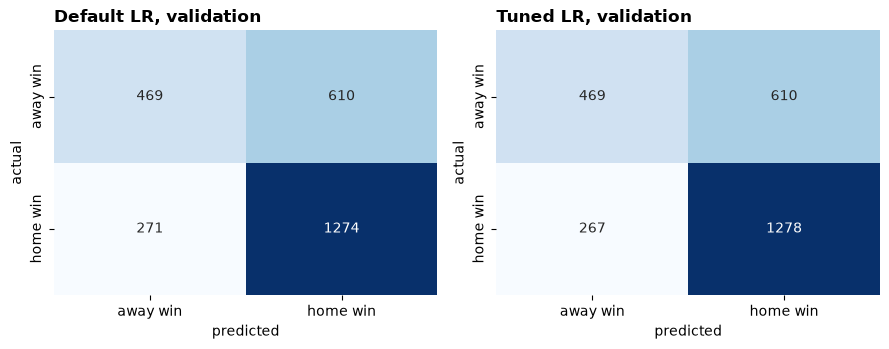

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
plot_cm(axes[0], y[is_val], p_default["validation"], "Default LR, validation")
plot_cm(axes[1], y[is_val], p_lr["validation"], "Tuned LR, validation")
plt.tight_layout(); plt.show()

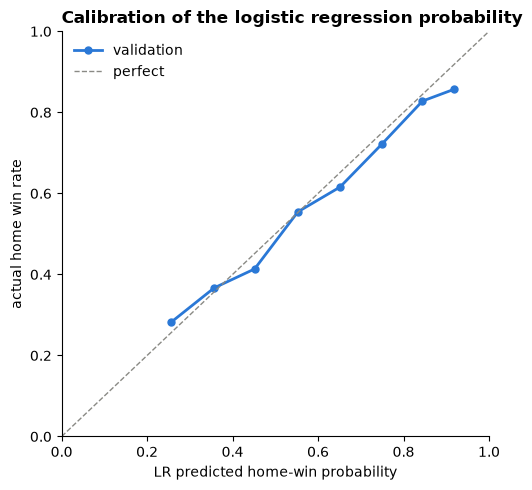

In [20]:
p_val = pd.Series(p_lr["validation"], index=y[is_val].index)
bins = pd.cut(p_val, np.linspace(0, 1, 11), include_lowest=True)
cal = pd.DataFrame({"pred": p_val, "won": y[is_val]}).groupby(bins, observed=True).agg(
    pred=("pred", "mean"), won=("won", "mean"), n=("won", "size"))
cal = cal[cal["n"] >= 30]

fig, ax = plt.subplots(figsize=(5.2, 5))
ax.plot(cal["pred"], cal["won"], marker="o", ms=5, lw=2, color=BLUE, label="validation")
ax.plot([0, 1], [0, 1], color=GRAY, ls="--", lw=1, label="perfect")
ax.set_xlabel("LR predicted home-win probability"); ax.set_ylabel("actual home win rate")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(loc="upper left")
ax.set_title("Calibration of the logistic regression probability")
plt.tight_layout(); plt.show()

### Step 9: observation
Observation: Forward-chaining tuning (5 folds, 2012–2016) selected C=0.01, with mean fold log loss 0.6028 (std 0.0136). Validation accuracy changes from 66.43% for the default model to 66.58% after tuning, and log loss from 0.6148 to 0.6142. The tuning gain is small compared with variation between folds.

The tuned model reaches 67.43% accuracy on train and 66.58% on validation, with ROC-AUC 0.7198 / 0.7029 and log loss 0.5983 / 0.6142. Validation accuracy is 7.70 percentage points above majority and 0.73 points above recorded tuned Elo. Its validation log loss is also lower than majority's 0.6775 and tuned Elo's 0.6182.

Fit: train and validation accuracy are within 0.85 percentage points; validation log loss is 0.0159 higher. This is a modest gap, but it does not by itself prove the absence of overfitting or establish underfitting. Seasonal variation and correlated features also matter when interpreting the model. The CSV's Elo features use home advantage=100, whereas standalone tuned Elo uses 75.

Next steps: the selected settings remain fixed for the final comparison. Test evaluation remains disabled, so these results do not establish performance in the COVID-heavy test seasons. Upstream feature construction must still satisfy the project's leakage checks; loading the combined CSV does not independently verify its history calculations.
